# 합성곱 신경망 (CNN)

## CNN
> ### 배경

>> 1) 이미지 인식 방법 차이
- 컴퓨터와 달리 사람은 이미지를 구성하는 모든 픽셀을 하나하나 살펴보면서 물체를 인식하지 않음
- 사람은 강아지 이미지를 보고 강아지라는 것을 자연스럽게 인식할 수 있지만, 컴퓨터는 이미지 자체를 사람처럼 이해하지 못함
- 그래서 컴퓨터는 이미지를 작은 픽셀 단위로 구분하고, 각 픽셀에 저장된 색상과 밝기 등의 숫자 정보를 처리
- 컴퓨터에게 이미지는 하나의 강아지 사진이 아니라 **수많은 픽셀 값이 모여 만들어진 숫자 데이터**

>> 2) MLP와 CNN의 구조 비교
- MLP는 입력된 데이터를 FC Layer에 전달하여 학습하는 구조
- CNN은 이미지의 공간적 특징을 유지하면서 Conv와 Pool을 반복하여 이미지의 특징을 추출
- MLP와 CNN의 가장 큰 차이점은, CNN이 FC Layer를 적용하기 전 Conv와 Pool을 이용해 이미지의 특징을 학습하는 과정이 추가된다는 점

>> 3) CNN
- 특징 추출 (Feature Learning)
    - Convolution Layer
    필터(Kernel)를 이미지 위에서 이동시키며 모서리, 질감, 형태 등 이미지의 다양한 특징을 추출
    - Pooling Layer
    추출된 특징 맵의 크기를 줄이고 중요한 특징을 유지하여 연산량을 감소시킴
- Flatten
여러 차원으로 이루어진 특징 맵을 FC Layer에 입력할 수 있도록 1차원 배열로 변환
- 분류 (Classification)
    - Fully Connected Layer
    추출된 특징들을 종합하여 이미지가 어떤 클래스에 속하는지 최종적으로 분류

> ### CNN을 사용하는 이유

>> MLP의 한계
- MLP는 이미지를 1차원 배열로 펼쳐서 입력받고, 각 픽셀 위치에 대응하는 가중치를 학습
- 숫자 1이 조금만 이동해도 기존에 값이 있던 픽셀 위치에는 0이 들어가고, 새로운 위치에 픽셀 값이 들어가면서 입력 데이터가 크게 달라지는 오류가 발생
- 즉, 학습 데이터에서 보지 못한 위치나 형태의 변화가 발생하면 기존의 숫자로 인식하지 못할 가능성이 높아져 성능이 크게 저하되는 한계가 존재

>> CNN에서는
- **CNN은 특정한 특징이 정확히 어느 픽셀 위치에 있는지만 보는 것이 아니라, 이미지 안에 해당 특징이 존재하는지를 효과적으로 학습**

>> 파라미터 폭발 (Parameter Explosion)
- MLP의 경우 완전연결(Fully connected) 구조로 인한 파라미터 급증이 이루어지며, 가중치 수가 이미지 픽셀의 개수만큼 생성됨
- 따라서 과적합 가능성 상승, 이미지가 클수록 학습이 느리다는 한계가 존재

>> CNN에서는
- CNN은 이미지 전체의 픽셀을 다음 계층의 모든 노드에 연결하는 대신, 작은 영역에만 필터를 적용하는 부분 연결 구조를 사용
- 일한 필터의 가중치를 이미지의 여러 위치에서 공유하기 때문에, 이미지 전체를 처리하더라도 위치마다 새로운 가중치를 만들 필요가 없음
- 따라서 이미지 크기가 커지더라도 필터의 크기와 개수가 동일하다면 **파라미터 수는 크게 증가하지 않음**

>> 공간 정보 손실 (Loss of Spatial Info)
- MLP는 이미지를 입력받을 때 2차원 또는 3차원으로 구성된 이미지 데이터를 1차원 벡터로 펼치는 Flatten 과정을 거침
- 이 과정에서 픽셀의 숫자 값 자체가 사라지는 것은 아니지만, 원래 이미지에서 어떤 픽셀들이 서로 가까이 있었는지에 대한 2차원 공간 구조가 명시적으로 유지되지 않음
- 따라서 MLP는 픽셀 간의 위치 관계나 주변 픽셀들이 모여 만들어내는 특징을 직접적으로 활용하기 어렵다는 한계 존재

>> CNN에서는
- CNN은 이미지를 입력받을 때 처음부터 1차원으로 펼치지 않고, H × W × C 형태의 다차원 구조를 유지한 상태로 처리
    - Convolution Layer는 이미지의 작은 영역을 대상으로 연산하기 때문에 주변 픽셀 간의 관계와 위치 정보를 활용 가능
    - Pooling Layer 역시 특징 맵의 공간적 구조를 어느 정도 유지하면서 크기를 줄임
    - 이후 여러 계층을 거쳐 이미지의 특징을 추출한 다음 Flatten을 적용해 1차원 벡터로 변환
- 즉, CNN은 이미지를 바로 Flatten하는 MLP와 달리, 이미지의 공간적 특징을 먼저 학습한 후 Flatten을 수행
- 따라서 픽셀의 위치 관계와 주변 영역의 특징을 활용하는 데 유리하고, 이미지 데이터를 효과적으로 학습 가능

> ### 합성곱(Convolution)과 풀링(Pooling)

>> Convolution Layer

개념
- Convolution Layer는 입력 이미지 전체를 일정한 크기의 필터(Filter)로 훑으면서 이미지의 특징을 추출하고 학습하는 계층
- 입력 데이터에 필터(Filter)를 적용하여 연산을 수행하고, 그 결과를 새로운 데이터로 만들어 내는 과정을 담당
- 필터(Filter)는 수직선, 수평선, 모서리, 질감 등과 같은 이미지의 특정한 패턴이나 특징을 감지하는 역할을 함

Feature Map
- 정의
    - Convolution 연산을 통해 생성되는 결과 데이터
    - 필터가 이미지의 여러 위치에서 계산한 결과값을 모아 하나의 Feature Map을 구성
    - 필터가 특정 특징에 반응할수록 해당 위치의 Feature Map 값이 커진다는 특징이 존재

- 차원 결정 방식
    - Feature Map의 개수는 사용하는 필터의 개수에 따라 결정
    - 예를 들어 RGB 이미지에 3 × 5 × 5 크기의 필터 하나를 적용하면 Feature Map 하나가 생성
    - 여기서 앞의 3은 입력 채널 수, 5 × 5는 필터의 공간적 크기를 의미

>> Padding

개념
- Padding은 Convolution 연산을 수행하기 전에 입력 이미지의 가장자리에 추가적인 픽셀을 삽입하는 방법
- 일반적으로 이미지 바깥쪽에 0을 추가하는 Zero Padding 방식을 많이 사용
- 필터는 입력 이미지의 범위 안에서만 이동할 수 있기 때문에 Padding을 적용하지 않으면 가장자리 영역은 필터가 적용되는 횟수가 상대적으로 적게 됨
- adding은 이러한 문제를 보완하고 Feature Map의 크기를 조절하는 역할

효과
- Padding을 적절하게 적용하면 Convolution 연산으로 인해 이미지의 크기가 지나치게 작아지는 것을 방지 가능
- **따라서 Padding은 이미지의 공간적 크기를 유지하면서 가장자리의 특징까지 학습할 수 있도록 하는 역할**

>> Stride (보폭)

**Stride = 1**

- 한 칸씩 이동
- 이미지의 여러 위치를 세밀하게 확인
- Feature Map의 크기가 상대적으로 큼

**Stride = 2**

- 두 칸씩 이동
- 일부 위치를 건너뛰며 연산
- Feature Map의 크기가 상대적으로 작음

Stride가 커질수록 **필터가 한 번에 이동하는 거리가 늘어나므로 입력 이미지에서 연산하는 위치가 줄어듦**

그 결과 Feature Map의 가로와 세로 크기가 작아짐 & 처리해야 할 데이터의 양 감소

따라서 Stride는 **특징을 얼마나 세밀하게 추출할지와 연산 효율을 어떻게 조절할지 결정하는 요소**

>> Pooling

개념
- Pooling은 이미지의 작은 위치 변화에 대한 민감도를 낮춰 모델이 특징을 더 안정적으로 인식할 수 있도록 도와줌
- 일정한 크기의 영역을 설정하고, 해당 영역에 포함된 값들을 하나의 값으로 요약
- 일반적으로 2 × 2 크기의 영역을 사용하며, 각 영역에서 최댓값이나 평균값을 계산하는 방식이 있음
- Pooling을 통해 이미지의 공간적 크기를 축소하고, 이후 단계에서 처리해야 하는 데이터의 양을 줄일 수 있음

Pooling의 종류
- **Max Pooling**
    
    지정된 영역 안에서 가장 큰 값을 선택하는 방식
    
- **Average Pooling**
    
    지정된 영역 안에 있는 모든 값의 평균을 계산하는 방식

장단점
- 장점
    - 차원 축소로 계산량 감소
    - 위치 변화에 대한 강건성
    - 과적합 방지에 도움
    - 노이즈 영향 완화

- 단점
    - 정보 소실의 위험
    - 정확한 위치 정보 감소


## 이미지 딥러닝 응용
> ### 이미지 분류 (Image Classification)

이미지 분류
- 이미지를 수치 데이터(픽셀 값)로 인식 → 사전 정의된 클래스 중 하나로 분류

**AlexNet** 
- 비교적 단순한 구조, 초기 CNN 모델들 
- 작은 데이터셋이나 학습 개념 설명용으로 적절

**VGG** 
- 더 깊은 구조, 복잡한 블록 구조 적용
- 계산량 증대, 메모리 요구 높음 

**ResNet**
- Residual 연결 (skip connections) → 매우 깊은 네트워크 가능
- 과적합 주의, batch size / regularization 조절 필요

**Vision Transformer (ViT)** 
- Transformer 구조 응용 → 패치 기반 입력 처리
- 이미지와 순차 처리 모델의 결합, 대규모 데이터 필요

**ViT(Vision Transformer)**
- 이미지를 작은 패치(Patch) 단위로 나누고, 이를 Transformer에 입력하여 이미지의 특징을 학습하는 모델
- CNN처럼 필터를 반복적으로 적용하는 대신 Attention을 활용해 이미지 패치 간의 관계를 학습한다는 점이 특징

**CNN의 확장 가능성**
- **YOLO (You Only Look Once)**
- CNN은 이미지 전체를 하나의 클래스로 분류하는 작업뿐 아니라, 이미지 안에 존재하는 여러 객체를 찾아내는 작업에도 활용됨
- 대표적인 모델인 YOLO는 이미지 안의 사람, 자동차, 자전거 등을 각각 탐지하고, 객체의 종류와 위치를 동시에 예측

> ### 객체 탐지 (Object Detection)
- 객체 탐지는 이미지 안에 있는 개별 객체의 종류와 위치를 함께 예측

**Bounding Box**
- 이미지에서 객체가 위치한 영역을 둘러싸는 사각형
- 객체 탐지 모델은 사각형의 위치와 크기를 예측하여 이미지 안에서 객체가 어디에 있는지 표시
- 일반적으로 중심 좌표 (x,y), 너비 (w), 높이 (h)를 이용하여 위치를 표현

모델 적용 방식
- CNN으로 Feature Map을 얻고 그 위에 두 개의 head를 올리는 구조
    - **Classification Head : 객체의 종류 예측**
        - 이미지에서 탐지한 객체가 어떤 종류에 속하는지 예측
    - **Regression Head : 객체의 위치 좌표 예측**
        - 객체를 둘러싸는 Bounding Box의 위치와 크기를 예측
        - 중심 좌표와 너비, 높이 등의 값을 계산하여 객체가 이미지의 어느 위치에 있는지 표시

    - 대표 모델 : YOLO, Faster R-CNN, SSD

> ### 이미지 캡셔닝 (Image Captioning)
- 이미지의 내용을 자연어 문장으로 표현하는 작업
- 이 과정에서 이미지 특징을 추출하는 CNN과 문장을 생성하는 RNN이 함께 사용됨
- 객체에 대한 판단을 넘어 객체들 간의 관계를 파악하고 자연어 형태로 표현하는 작업

- **모델 적용 방식 : CNN과 RNN**
    - **CNN : 이미지 특징 추출**
        - 이미지에서 사람, 자전거, 도로와 같은 객체 및 시각적 특징을 추출
    - **RNN : 문장 생성**
        - CNN이 추출한 이미지 특징을 바탕으로 단어를 순서대로 생성
        - 이전에 생성한 단어 정보를 활용하여 다음에 올 단어를 예측하고 하나의 문장을 완성



## RNN (Recurrent Neural Network)
> ### 순차(Sequence) 데이터

데이터의 순서가 의미를 갖는 데이터로, 순서를 바꾸면 정보가 달라지는 데이터

>> 세부분류
- 순서의 기준
    - 시간 순, 시간 외(위치, 순번 등)
- 자료형
    - 수치형
    - 범주형

>> 기존 정형 데이터 vs. 순차 데이터
- **정형 데이터** : 고객 A, B, C 행 순서를 C, A, B로 바꿔도 → **의미 변화 X**
- **순차 데이터** : "개가 사람을 물었다" → "사람이 개를 물었다" → **완전히 다른 의미**

- 기존 머신러닝 기법(회귀, 결정트리, SVM)은 정형 데이터를 전제로 설계되어서 순차 데이터를 처리하는 데는 한계가 존재

    -> 순차 데이터를 처리할 별도의 모델이 필요

    #### => **RNN**



> ### RNN(Recurrent Neural Network, 순환신경망)의 구조와 원리

>> 1) 구조
- 기존신경망과 비교했을 때 가장 큰 차이점은 은닉층에 순환 구조가 존재하는 것

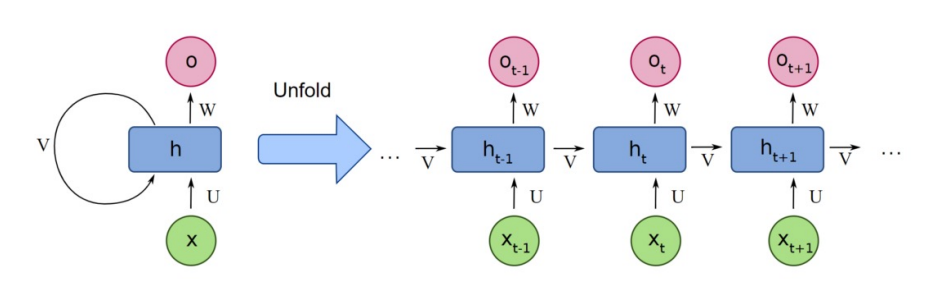

- **입력층** ($x$) : 각 시점 t에 들어오는 입력 데이터  xₜ를 받는 곳
- **은닉층** ($h$): 현재 입력 xₜ와 이전 시점의 은닉 상태 hₜ₋₁를 함께 받아 새로운 은닉 상태 hₜ를 만드는 곳
- **출력층** ($o$): 은닉 상태 hₜ를 바탕으로 시점 t의 결과 oₜ를 내보내는 곳
- **입력 가중치** ($U$): 입력 데이터 xₜ를 은닉층으로 보낼 때 붙는 가중치
- **순환 가중치** ($V$) : 이전 은닉 상태 hₜ₋₁를 현재 은닉층으로 보낼 때 붙는 가중치
- **출력 가중치** ($W$): 은닉 상태 hₜ를 출력 oₜ로 바꿀 때 붙는  가중치

>> 2) 원리
- **핵심**  : 매 시점마다 현재 시점 입력값과 이전 시점 은닉상태를 이용해 현재의 은닉상태를 계산하고 그 결과를 다음 시점으로 넘겨줌
- **은닉 상태(**$hₜ$) **계산** : 현재 입력 $xₜ$ + 이전 은닉 상태 $hₜ₋₁$ → 새로운 은닉 상태 $hₜ$

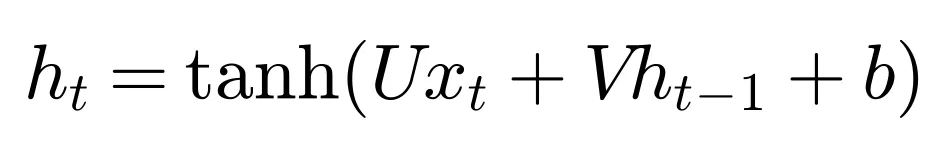
- $b$: 편향

- **출력 계산** : 은닉 상태 $hₜ$로 현재 시점의 출력을 만듦

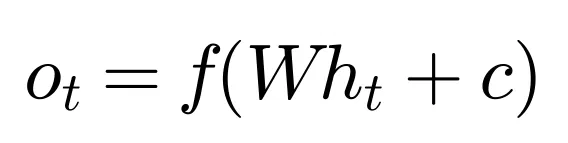

- $f(활성화함수)$
    - 이진 분류 문제라면 시그모이드 함수
    - 다중 분류 문제라면 소프트맥스 함수

        - 입력받은 각 점수를 지수함수로 변환한뒤 전체 클래스의 지수 합으로 나누어줌
        - 출력값은 0에서 1사이 값
        - 전체 출력값의 합은 항상 1
    - $c$: 편향


>> RNN 아키텍쳐
- One to Many - 하나의 입력에서 시퀀스 출력
- Many to One - 시퀀스 입력에서 하나의 값 출력
- Many to Many - 시퀀스 입력에서 시퀀스 출력

> ### RNN의 한계 및 장기 의존성 문제

> RNN의 한계점

시간에 따른 역전파(Back Propagation Through Time) 구조
- RNN은 순전파를 통해 시퀀스를 처리한 뒤, 시간을 거슬러 올라가며(BPTT) 오차를 전파하여 가중치 기울기를 누적 계산
    - chain rule에 의해 한 시점을 거슬러 갈 때마다  $∂hₜ/∂hₜ₋₁$ = (활성화 함수 미분값) × (순환 가중치)가 곱해짐

>> **[RNN에서의 Chain Rule]**

RNN은 h₁ → h₂ → h₃ → 출력층 → 오차 L 순서로 이어졌다고 했을 때

 h₁의 변화가 최종 오차(L)에 미치는 영향(기울기)을 구하려면, 중간 단계를 모두 곱해야 함

**→ ∂L/∂h₁ = ∂L/∂h₃ × ∂h₃/∂h₂ × ∂h₂/∂h₁**

$$
\frac{\partial h_t}{\partial h_{t-1}} = \underbrace{\text{diag}\left(g'(a_t)\right)}_{\text{활성화 함수 미분값}} \ \times\underbrace{V}_{\text{순환 가중치}}
$$

- 같은 순환 가중치(V)를 모든 시점이 공유 → 같은 값이 계속 곱해지는 등비수열 형태
    - k시점 전까지 거슬러 가면 이 값이 k번 곱해짐 (Vᵏ 꼴)

>> 기울기 소실
- 역전파 과정에서 기울기가 과거 시점으로 갈수록 점점 작아져 0에 가까워지는 현상
- 발생 원인
    
    $$
    \frac{\partial h_t}{\partial h_{t-1}} = \underbrace{\text{diag}\left(g'(a_t)\right)}_{\text{활성화 함수 미분값}} \ \times\underbrace{V}_{\text{순환 가중치}} < 1
    $$
    
    - tanh 미분값은 최대 1, 대부분 1보다 작음
    - V의 크기가 1보다 작으면 반드시 소실, 조금 커도 소실될 수 있음
- 특징
    - 기본 RNN에서 기울기 폭주보다 훨씬 자주 발생 (tanh미분값 ≤ 1 이기 때문에)



>> 기울기 폭주
- 역전파 과정에서 기울기가 과거 시점으로 갈수록 점점 커져 매우 큰 값이 되는 현상
- 발생 원인
    
    $$
    \frac{\partial h_t}{\partial h_{t-1}} = \underbrace{\text{diag}\left(g'(a_t)\right)}_{\text{활성화 함수 미분값}} \ \times\underbrace{V}_{\text{순환 가중치}} > 1
    $$
    
- 특징
    - 가중치가 크게 튀면서 오차가 갑자기 치솟거나 진동함
    - 심하면 오차값이 너무 커져 NaN(계산 불가)이 발생하고 학습이 중단됨

>> 느린 훈련 시간
- RNN은 시점을 하나씩 순서대로만 계산할 수 있어서, 시퀀스가 길수록 학습에 시간이 오래 걸리게 됨
- 특징
    - 시퀀스 길이에 비례해 계산 시간이 늘어남
    - 역전파를 위해 모든 시점의 은닉 상태를 저장해야 해서 메모리 부담도 큼
- CNN과의 차이점
    - CNN : 필터가 각 위치를 독립적으로 계산 → 여러 위치를 동시에(병렬로) 처리 가능
    - RNN : 앞 시점 결과가 있어야 다음 계산 가능

> 장기 의존성 문제 (Long-Term Dependency Problem)

시퀀스에서 **관련된 정보가 멀리 떨어져 있을수록**, RNN이 그 관계를 **기억하고 학습하지 못하는** 문제
- 중요한 정보는 잊지 않고 오래 기억하고, 불필요한 정보는 잊는 메모리 구조가 필요

## LSTM & GRU 
> **LSTM (Long Short-Term Memory)**

기억을 두 개의 상태로 나눠서 관리
- 셀 상태 -> 장기 기억
- 은닉 상태 -> 단기 기억 & 출력

기존 RNN은 은닉 상태 h 하나에 모든 걸 덮어썼지만, LSTM은 오래 남길 기억(셀 상태)을 따로 빼둠

>> **세 개의 게이트**

1. **Forget Gate**
→ 장기 기억에서 더 이상 필요 없는 내용을 삭제
2. **Input Gate**
→ 새로 들어온 정보 중 중요한 것만 장기기억에 저장
3. **Output Gate**
→ 장기기억 중 지금 필요한 부분만 꺼내 단기기억으로 내보냄

>> LSTM (Long Short Term Memory) 구조

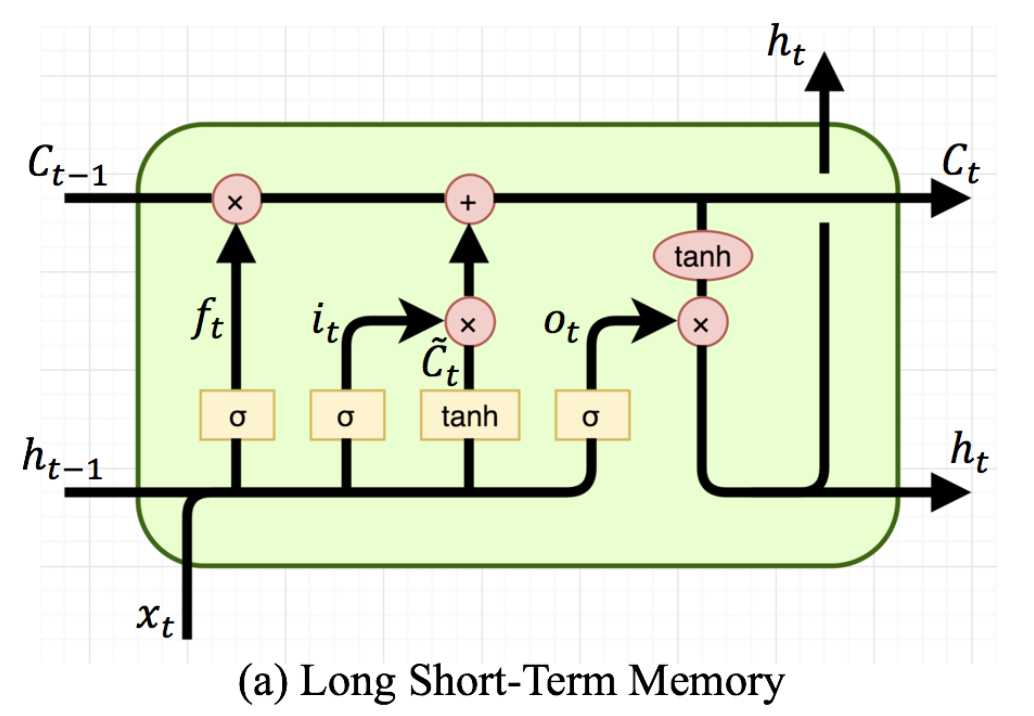
- 셀 상태(Cell State - 장기기억) : 구조도 맨 위를 가로지르는 선 → 시점을 따라 쭉 이어짐
    - 정보가 큰 변화 없이 타고 다음 시점으로 흘러감
    - 게이트가 정보를 **빼거나(잊기)** **더해서(기억하기)** 조절
    
    ⇒ 기억할 내용과 잊어버릴 내용을 선택해, 중요한 정보를 오래 가져갈 수 있음

>> 장단점

**장점**

- 셀 상태의 덧셈 구조 덕분에 기울기가 먼 과거까지 전달 → 기울기 소실 완화
- 게이트로 중요한 정보는 남기고 불필요한 정보는 지움 → 장기 의존성 학습 가능
- 문장 번역, 음성 인식 등 긴 시퀀스 과제에서 RNN보다 좋은 성능

**단점**

- 계산량이 많아 학습이 느리고 메모리도 많이 사용
- 여전히 시점을 순서대로 계산해야 함 → 병렬 처리 불가 (느린 훈련 시간 문제는 그대로)
- 기울기 소실을 "완화"한 것이지 완전히 없앤 것은 아님 → 매우 긴 시퀀스에서는 여전히 한계

⇒ 더 단순한 구조인 GRU 등장의 배경

---

> **GRU (Gated Recurrent Unit)**

기억을 하나로 통합해서 관리
- 셀 상태와 은닉 상태로 나누지 않고, 은닉 상태 $h$ 하나에 기억과 출력을 모두 포함

>> **두 개의 게이트**

1. **Update Gate** → 과거 기억 : 새 정보 = 몇 : 몇 
→ 예) 과거 70 : 새 정보 30으로 섞기
→ LSTM의 Forget Gate + Input Gate를 게이트 하나로 처리
2. **Reset Gate** → 과거 기억을 얼마나 무시할건지 
→ 새 정보를 해석할 때 과거 기억을 얼마나 참고할지 결정

>> GRU (Gated Recurrent Unit) 구조

GRU = LSTM의 핵심 아이디어(게이트로 정보를 선택적으로 기억·삭제)는 유지하면서, 구조를 단순하게 줄인 모델
- LSTM : 상태 2개(셀 상태 + 은닉 상태), 게이트 3개
- GRU : 상태 1개(은닉 상태), 게이트 2개
    
    ⇒ LSTM을 더 가볍게 만든 버전

>>> LSTM과의 차이점

#### 1. Forget gate와 Input gate를 Update gate 하나로 통합

- Update gate $zₜ$ 하나로 ‘과거 기억 : 새 정보 = 몇 : 몇’ <u></u>을 한 번에 결정
- $hₜ = (1 − zₜ) ⊙ hₜ₋₁ + zₜ ⊙ h̃ₜ$
- ex) $zₜ$ = 0.3 → 과거 기억 70% + 새 정보 30%

#### 2. Reset gate를 사용

- Reset gate $rₜ$로 "과거 기억을 얼마나 무시할지"를 먼저 정한 뒤 후보 정보 $h̃ₜ$를 만듦
- $rₜ$ ≈ 0 → 과거를 거의 무시하고 현재 입력 위주로 새 정보를 만듦
- ex) 문장이 끝나고 새 문장이 시작될 때, 이전 문맥을 끊고 새로 시작

#### 3. Output gate가 없음

- 출력을 거르는 단계 없이 은닉 상태 $hₜ$를 그대로 출력

#### 4. Gate의 개수가 3개에서 2개로 감소

- 파라미터가 LSTM의 약 3/4 → 계산량이 줄어 학습 시간이 짧아짐
- 그런데도 성능은 LSTM과 비슷하거나, 과제에 따라 더 좋은 경우도 있음

>> 장단점 (vs LSTM)

장점
- 상태 1개, 게이트 2개로 구조가 단순하여 이해와 구현이 쉬움
- 파라미터가 적어 학습 속도가 빠르고 메모리 사용량이 적음
- 파라미터가 적어 데이터 수가 적을 때도 학습이 안정적임
- Update gate 하나로 기억 갱신을 간단히 처리함
- 많은 과제에서 LSTM과 비슷한 성능을 보임

단점
- 장기 기억과 출력을 분리하지 못함
- 데이터가 많고 복잡한 과제에서는 LSTM이 더 나을 수 있음
- 잊는 양과 더하는 양을 따로 조절할 수 없어 정교함이 떨어짐
- 항상 LSTM보다 낫다고 단정할 수는 없음


## Seq2Seq
- 정의: 입력 시퀀스를 받아 다른 시퀀스를 출력하는 모델

- 핵심 특징: 입력과 출력의 길이가 달라도 동작 가능 (기존 RNN과의 가장 큰 차이)

    - 예시: "I am a student" (4단어) → "je suis étudiant" (3단어)

    -언어별 어순 차이 및 표현 단어 수의 차이를 효과적으로 처리

- 구조적 특징: 기존 RNN의 Many-to-Many 구조를 두 개의 RNN(LSTM/GRU)으로 나누어 구현

- 활용 분야: 기계 번역, 챗봇 (질문 → 답변), 문서 요약, 음성 인식

> 전체적인 작동 원리와 구조
- 인코더(Encoder)와 디코더(Decoder) 두 개의 모듈로 구성

- 내부 셀: 장기 의존성(Long-term Dependency) 문제 해결을 위해 주로 LSTM 또는 GRU 사용

> 세부 구성 요소

>> 1) 인코더 (Encoder)
- 정의: 입력 문장의 모든 단어를 순서대로 읽고, 문장 전체의 정보를 하나의 벡터(컨텍스트 벡터)로 압축하는 LSTM

- 작동 원리:

    - 단어 토큰화: 입력 문장을 단어 단위로 분할 ("I", "am", "a", "student")

    - 임베딩(Embedding): 각 단어를 수치화된 숫자 벡터로 변환

    - LSTM 셀 순차 입력: 매 시점의 은닉 상태(Hidden State)가 다음 시점으로 전달되며 정보가 누적

    - 컨텍스트 벡터 생성: 마지막 시점의 은닉 상태가 문장 전체 정보를 담은 컨텍스트 벡터가 되어 디코더로 전달


>> 2) 디코더 (Decoder)
- 정의: 컨텍스트 벡터를 받아 출력 문장을 한 단어씩 순서대로 생성하는 LSTM

- 작동 원리:

    - 컨텍스트 벡터를 디코더 LSTM의 첫 은닉 상태로 전달받음

    - 시작 신호인 <sos>(Start of Sequence)를 첫 입력으로 투입

    - 매 시점 Softmax 함수로 다음 단어의 확률을 계산 후, 가장 확률이 높은 단어를 선택 (argmax)

    - 방금 예측한 단어를 다음 시점의 입력으로 재투입 (<sos> → "je" → "suis" → "étudiant")

    - 종료 신호인 <eos>(End of Sequence)가 나오면 단어 생성 종료

>> 3) 컨텍스트 벡터 (Context Vector)
- 정의:

    - 인코더가 입력 문장 전체를 읽고 만든 문장 요약 벡터

    - 인코더 LSTM의 마지막 시점 은닉 상태 (LSTM인 경우 셀 상태도 함께 전달)

    - 인코더와 디코더를 연결하는 유일한 통로

- 차원 설정 (Hyperparameter):

    - 컨텍스트 벡터의 크기 = 인코더 LSTM의 은닉 상태 크기

    - 보통 수백 차원(256, 512, 1024 등)으로 설정

    - 핵심 조건: 디코더 LSTM의 은닉 상태 크기도 동일한 값으로 맞춰야 바로 이어받을 수 있음

    - 차원 크기에 따른 트레이드오프:

        - 크기가 클 때: 더 많은 정보를 저장할 수 있지만, 계산량이 증가하고 과적합(Overfitting) 위험이 있음

        - 크기가 작을 때: 계산 속도가 빠르지만, 긴 문장의 정보를 충분히 담지 못함


> Seq2Seq의 한계: 병목 현상 (Bottleneck)
- 고정된 Context Vector에 소스 문장의 정보 압축 → 병목 현상 발생
- 고정된 길이에 입력 시퀸스의 모든 정보를 담지 못하고 손실될 수 있다.
- 특히 긴 입력 시퀸스의 경우 정보 손실이 더 심각하며, 이는 모델 성능 하락으로 이어진다.
